## Lab | LangGraph

In [23]:
!pip install -U langgraph langchain-openai python-dotenv

In [4]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


```
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

In [14]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.messages import HumanMessage, SystemMessage


class ComplaintState(TypedDict):
    complaint: str
    category: str
    lore: str
    findings: str
    resolution: str
    summary: str
    workflow_path: List[str]
    status: str

VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

initial_state = {
           "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
           "category": "",
           "lore": "",
            "findings": "",
            "resolution": "",
           "workflow_path": [],
           "status": "new",
       }
print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'lore': '', 'findings': '', 'resolution': '', 'workflow_path': [], 'status': 'new'}


In [16]:
def intake(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")
 
    complaint = state["complaint"]
 
    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
        - portal: Issues with portal timing, location, or behavior
        - monster: Issues with creature behavior (demogorgons, etc.)
        - psychic: Issues with psychic abilities or limitations
        - environmental: Issues with electricity, weather, or physical environment
        - other: Anything else
        
        Complaint: {complaint}
        
        Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""
 
    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower().strip(".")
 
    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }
 
    print(f"[INTAKE] Categorized as: {category}")
    return new_state


def validate(state: ComplaintState) -> dict:
    """Step 2: Validate - is this complaint something we can investigate?"""
    is_valid = state["category"] in VALID_CATEGORIES
    return {
        "workflow_path": state["workflow_path"] + ["validate"],
        "status": "validated" if is_valid else "invalid",
    }


def route_after_validate(state:ComplaintState) ->str:
     """Conditional edge: decides the next node."""
     return "investigate" if state["status"] == "validated" else "reject"


def investigate(state: ComplaintState) -> dict:
    """Step 3: Investigate - ground the complaint in lore, then analyze it."""
    print("\n[INVESTIGATE] Looking up lore and analyzing...")

    lore = LORE[state["category"]]  # safe: validate guarantees a valid category

    prompt = f"""You are a Hawkins Lab researcher investigating a complaint.
            Relevant lore ({state['category']}):
            {lore}
            Complaint: {state['complaint']}
            Analyze the complaint using ONLY the lore above. Give:
            1. The root cause of the issue
            2. Which part of the lore explains it
            3. Anything the lore does NOT cover (so we don't invent facts)
            Keep it under 120 words."""

    response = llm.invoke([HumanMessage(content=prompt)])

    return {
        "lore": lore,
        "findings": response.content.strip(),
        "workflow_path": state["workflow_path"] + ["investigate"],
        "status": "investigated",
    }



def resolve(state: ComplaintState) -> dict:
    """Step 4: Resolve - turn the findings into an actionable answer."""
    print("\n[RESOLVE] Drafting resolution...")

    prompt = f"""You are drafting a reply to a complainant.
            Complaint: {state['complaint']}
            Investigation findings: {state['findings']}
            Write a short, practical resolution (max 100 words):
            - Answer the complaint directly
            - Give 2-3 concrete steps they can take
            - If the findings note a gap in the lore, say so honestly instead of guessing"""

    response = llm.invoke([
        SystemMessage(content="You are a calm, helpful Hawkins Lab support agent."),
        HumanMessage(content=prompt),
    ])

    return {
        "resolution": response.content.strip(),
        "workflow_path": state["workflow_path"] + ["resolve"],
        "status": "resolved",
    }


def close(state: ComplaintState) -> dict:
    """Step 5: Close - build the final record. No LLM call needed."""
    print("\n[CLOSE] Building final record...")

    path = state["workflow_path"] + ["close"]

    summary = (
        f"CASE CLOSED\n"
        f"Category:   {state['category']}\n"
        f"Complaint:  {state['complaint']}\n"
        f"Findings:   {state['findings']}\n"
        f"Resolution: {state['resolution']}\n"
        f"Path:       {' -> '.join(path)}"
    )

    return {
        "summary": summary,
        "workflow_path": path,
        "status": "closed",
    }


def reject(state: ComplaintState) -> dict:
    """Terminal branch for invalid complaints."""
    path = state["workflow_path"] + ["reject"]

    summary = (
        f"CASE REJECTED\n"
        f"Complaint: {state['complaint']}\n"
        f"Reason:    categorized as '{state['category']}', which is outside "
        f"the scope of this desk (portal, monster, psychic, environmental).\n"
        f"Path:      {' -> '.join(path)}"
    )

    return {
        "summary": summary,
        "workflow_path": path,
        "status": "rejected",
    }

Test the nodes without graph

In [11]:
def apply(state: dict, update: dict) -> dict:
    """Merge a node's partial update into state, like LangGraph does."""
    return {**state, **update}


state = dict(initial_state)  # copy so you don't mutate the original

state = apply(state, intake(state))
print("category:", state["category"], "| status:", state["status"])

state = apply(state, validate(state))
print("status after validate:", state["status"])
print("route ->", route_after_validate(state))

state = apply(state, investigate(state))
print("findings:", state["findings"])

state = apply(state, resolve(state))
print("resolution:", state["resolution"])

state = apply(state, close(state))
print("path:", state["workflow_path"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
category: portal | status: intake
status after validate: validated
route -> investigate

[INVESTIGATE] Looking up lore and analyzing...
findings: 1. The root cause of the issue is the unpredictable nature of the Downside Up portal's opening times, which vary daily.

2. The part of the lore that explains this is that portals open when the barrier between worlds is weak, and their timing is influenced by electrical activity rather than a fixed schedule.

3. The lore does not cover specific methods for predicting electrical activity or how to measure the strength of the barrier between worlds. It also does not provide information on the duration of portal openings or any external factors that might influence their occurrence.

[RESOLVE] Drafting resolution...
resolution: Dear [Complainant's Name],

Thank you for your feedback regarding the Downside Up portal's unpredictable opening times. Unfortunately, the lore does not pr

### Build the Graph

In [21]:
graph=StateGraph(ComplaintState) 
graph.add_node("intake",intake)
graph.add_node("validate",validate) 
graph.add_node("reject",reject) 
graph.add_node("investigate",investigate)
graph.add_node("resolve",resolve)
graph.add_node("close",close)


graph.add_edge(START,"intake")
graph.add_edge("intake", "validate")
graph.add_conditional_edges("validate", route_after_validate, {"investigate":"investigate", "reject":"reject"})
graph.add_edge("investigate","resolve")
graph.add_edge("resolve","close")
graph.add_edge("close", END)
graph.add_edge("reject",END)

app=graph.compile()

In [25]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")


results = []
for complaint in test_complaints:
    state = dict(initial_state, complaint=complaint)
    result = app.invoke(state)
    results.append(result)
    print(result["workflow_path"], result["status"])


Testing workflow with sample complaints...


[INTAKE] Processing complaint...


[INTAKE] Categorized as: portal

[INVESTIGATE] Looking up lore and analyzing...

[RESOLVE] Drafting resolution...

[CLOSE] Building final record...
['intake', 'validate', 'investigate', 'resolve', 'close'] closed

[INTAKE] Processing complaint...
[INTAKE] Categorized as: monster

[INVESTIGATE] Looking up lore and analyzing...

[RESOLVE] Drafting resolution...

[CLOSE] Building final record...
['intake', 'validate', 'investigate', 'resolve', 'close'] closed

[INTAKE] Processing complaint...
[INTAKE] Categorized as: psychic

[INVESTIGATE] Looking up lore and analyzing...

[RESOLVE] Drafting resolution...

[CLOSE] Building final record...
['intake', 'validate', 'investigate', 'resolve', 'close'] closed

[INTAKE] Processing complaint...
[INTAKE] Categorized as: environmental

[INVESTIGATE] Looking up lore and analyzing...

[RESOLVE] Drafting resolution...

[CLOSE] Building final record...
['intake', 'validate', 'investigate', 'resolve', 'close'] closed

[INTAKE] Processing complaint...
[IN

### Visualize the Workflow Path

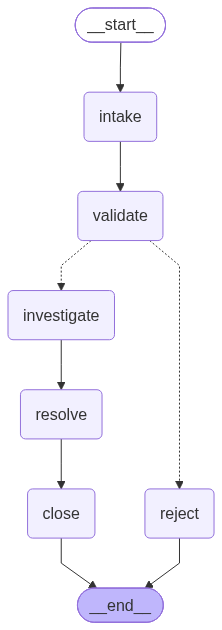

In [26]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [27]:
for r in results:
    print(" → ".join(r["workflow_path"]))

intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → reject


### Compare with LangChain

In [28]:
# Valid complaint: one LLM call, no graph, no lore
answer = llm.invoke([HumanMessage(content=test_complaints[0])])
print("SINGLE CALL:\n", answer.content)

# Invalid complaint: same thing
invalid = "My toaster is broken. Can you fix it?"
answer = llm.invoke([HumanMessage(content=invalid)])
print("\nSINGLE CALL (invalid):\n", answer.content)

SINGLE CALL:
 To predict when the Downside Up portal opens, you can follow these steps:

1. **Historical Data**: Gather data on the opening times of the portal over a period of time. Look for patterns or trends in the times it opens.

2. **Identify Patterns**: Analyze the data for any recurring patterns. For example, does it open at similar times on certain days of the week? Are there specific intervals between openings?

3. **External Factors**: Consider any external factors that might influence the opening times, such as events, lunar cycles, or other relevant occurrences.

4. **Create a Model**: If you have enough data, you could create a predictive model using statistical methods or machine learning techniques to forecast future opening times based on past behavior.

5. **Stay Updated**: Keep an eye on any announcements or updates from the source of the portal, as they may provide clues or schedules for when it will open.

6. **Community Insights**: Engage with communities or forum

| | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | Yes | No |
| Invalid complaint rejected? | Yes | No |
| Path visible? | Yes| No |
| Source of each claim? | Yes | No |
| Best for which client case? |high-stakes work where you must show how a decision was made | Quick prototypes, internal Q&A, brainstorming, or any case where auditsing the reasoning is not needed |